# IA GENERATIVA PARA LA GESTIÓN INDUSTRIAL - CERTAMEN 1
## Grupo 8
### Members: Renato Fernández, Vicente Vargas y Matías González

## Clasificación inteligente de residuos para reciclaje

## 1. Contexto y datos

En este proyecto se desarrollará un sistema de clasificación de imágenes para identificar distintos tipos de residuos y apoyar su correcta separación para el reciclaje. Uno de los problemas que se presentan al momento de reciclar es que muchas veces las personas no saben identificar correctamente los materiales o desconocen cómo deben desecharlos. Esto puede provocar que residuos reciclables terminen mezclados con otros materiales, dificultando su posterior tratamiento.

La idea principal es desarrollar un modelo capaz de reconocer el tipo de residuo a partir de una fotografía y utilizar esta clasificación dentro de una aplicación web. Para esto se trabajará con modelos preentrenados, comparando su desempeño para seleccionar el que entregue mejores resultados. Además, se incorporará inteligencia artificial generativa para entregar recomendaciones sobre cómo separar y disponer de los residuos según el material identificado. De esta manera, se busca que la aplicación no solamente clasifique imágenes, sino que también entregue información útil para apoyar las decisiones de reciclaje.

### Dataset utilizado

Para este análisis se utilizará **RealWaste**, un dataset desarrollado por Sam Single, Saeid Iranmanesh y Raad Raad en 2023, que contiene 4.752 fotografías de residuos tomadas en condiciones reales en una instalación de gestión de desechos en Australia. Las imágenes son a color, tienen una resolución de 524 × 524 píxeles y se encuentran clasificadas originalmente en nueve categorías.

En nuestro caso se trabajará solamente con cinco clases, correspondientes a los materiales que buscamos identificar mediante la aplicación:

| Clase | Cantidad de imágenes |
|---|---:|
| Plástico (Plastic) | 921 |
| Metal (Metal) | 790 |
| Papel (Paper) | 500 |
| Cartón (Cardboard) | 461 |
| Vidrio (Glass) | 420 |
| **Total** | **3.092** |

El dataset se encuentra disponible en Hugging Face y contiene todas las imágenes en un único conjunto, por lo que será necesario dividir los datos en entrenamiento, validación y prueba. Para esto se propone utilizar un 70%, 15% y 15%, respectivamente, procurando mantener una proporción similar de cada clase y evitando que imágenes repetidas aparezcan en diferentes conjuntos.

Una limitación importante es que las clases no tienen la misma cantidad de imágenes y que las fotografías fueron tomadas en un entorno específico. Esto podría afectar el desempeño del modelo al analizar fotografías nuevas con distintas condiciones de iluminación, fondos u objetos. Además, identificar el material de un residuo no significa necesariamente que pueda reciclarse, ya que esto también depende de sus características y de los sistemas de reciclaje disponibles.

**Fuente:** Single, S., Iranmanesh, S. y Raad, R. (2023). *RealWaste*. UCI Machine Learning Repository.

**Dataset:** https://huggingface.co/datasets/shahzaibvohra/realwaste

**Referencia original:** https://doi.org/10.3390/info14120633

**Licencia:** La versión de Hugging Face indica CC BY 4.0, mientras que los autores originales señalan CC BY-NC-SA 4.0. Para este trabajo se considerarán las condiciones de la licencia original.


## Librerías

In [5]:
import os, random, numpy as np, matplotlib.pyplot as plt, torch
from PIL import Image
from datasets import load_dataset
from sklearn.metrics import balanced_accuracy_score

DISP = "cuda" if torch.cuda.is_available() else "cpu"

### 2.1. Carga del dataset

Cargamos el dataset RealWaste desde Hugging Face para revisar cómo se encuentran organizadas las imágenes y sus respectivas categorías.

In [8]:
ds = load_dataset("shahzaibvohra/realwaste")
print(ds)
print(ds["train"].features)

C:\Users\renat\anaconda3\envs\ia_series\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\renat\.cache\huggingface\hub\datasets--shahzaibvohra--realwaste. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an admin

DatasetDict({
    train: Dataset({
        features: ['image'],
        num_rows: 4752
    })
})
{'image': Image(mode=None, decode=True)}


### 2.2. Selección de clases

Como el dataset original contiene nueve categorías, seleccionaremos solamente cinco para nuestro análisis: cartón, vidrio, metal, papel y plástico. Para esto utilizaremos los nombres originales de los archivos, que nos permiten identificar a qué categoría pertenece cada imagen.

In [31]:
# Recuperar las rutas originales de las imágenes
from datasets import Image as HFImage
ds_rutas=ds["train"].cast_column("image",HFImage(decode=False))

# Clases que utilizaremos
NOMBRES=["Cardboard","Glass","Metal","Paper","Plastic"]

# Identificar las clases según los nombres de los archivos
etiquetas=[os.path.basename(fila["image"]["path"]).split("_")[0] for fila in ds_rutas]

# Seleccionar solamente las imágenes de las 5 clases
indices=[i for i in range(len(etiquetas)) if etiquetas[i] in NOMBRES]
datos=ds["train"].select(indices)
datos=datos.add_column("label",[etiquetas[i] for i in indices])

# Revisar la cantidad de imágenes por clase
for c in NOMBRES:
    print(f"{c}: {datos['label'].count(c)} imágenes")
print("Total:",len(datos))

Cardboard: 461 imágenes
Glass: 420 imágenes
Metal: 790 imágenes
Paper: 500 imágenes
Plastic: 921 imágenes
Total: 3092


### 2.3. División y organización de los datos

Para preparar el entrenamiento de los modelos, dividiremos las imágenes en un 80% para entrenamiento y un 20% para validación, procurando mantener la proporción de cada clase. De esta manera, utilizaremos las imágenes de entrenamiento para que los modelos aprendan a identificar los residuos, mientras que las de validación nos permitirán evaluar y comparar su rendimiento.

In [49]:
# Dividir y guardar las imágenes
DATOS="datos"
random.seed(0)

for c in NOMBRES:
    fotos=[i for i,etiqueta in enumerate(datos["label"]) if etiqueta==c]
    random.shuffle(fotos)
    corte1=int(len(fotos)*0.7)
    corte2=int(len(fotos)*0.85)

    for parte,grupo in [("train",fotos[:corte1]),("val",fotos[corte1:corte2]),("test",fotos[corte2:])]:
        carpeta=f"{DATOS}/{parte}/{c}"
        os.makedirs(carpeta,exist_ok=True)
        for i in grupo:
            datos[i]["image"].convert("RGB").save(f"{carpeta}/{i:05d}.png")

# Mostrar las imágenes por clase
CLASES=sorted(os.listdir(f"{DATOS}/train"))
for c in CLASES:
    print(f"{c:18s} train = {len(os.listdir(f'{DATOS}/train/{c}')):4d} | val = {len(os.listdir(f'{DATOS}/val/{c}')):4d} | test = {len(os.listdir(f'{DATOS}/test/{c}')):4d}")


Cardboard          train =  322 | val =   69 | test =   70
Glass              train =  294 | val =   63 | test =   63
Metal              train =  553 | val =  118 | test =  119
Paper              train =  350 | val =   75 | test =   75
Plastic            train =  644 | val =  138 | test =  139


In [86]:
# Dividir y guardar las imágenes
DATOS="datos"
random.seed(0)

for c in NOMBRES:
    fotos=[i for i,etiqueta in enumerate(datos["label"]) if etiqueta==c]
    random.shuffle(fotos)
    corte=int(len(fotos)*0.8)

    for parte,grupo in [("train",fotos[:corte]),("val",fotos[corte:])]:
        carpeta=f"{DATOS}/{parte}/{c}"
        os.makedirs(carpeta,exist_ok=True)
        for i in grupo:
            datos[i]["image"].convert("RGB").save(f"{carpeta}/{i:05d}.png")

# Mostrar las imágenes por clase
CLASES=sorted(os.listdir(f"{DATOS}/train"))
for c in CLASES:
    print(f"{c:18s} train = {len(os.listdir(f'{DATOS}/train/{c}')):4d} | val = {len(os.listdir(f'{DATOS}/val/{c}')):4d}")

Cardboard          train =  368 | val =   93
Glass              train =  336 | val =   84
Metal              train =  632 | val =  158
Paper              train =  400 | val =  100
Plastic            train =  736 | val =  185


### 2.4. Evaluación común

Para comparar ambos modelos en igualdad de condiciones, utilizaremos las mismas 620 imágenes de validación y calcularemos la accuracy balanceada.

In [91]:
# Preparar las imágenes de validación
val=[(f"{DATOS}/val/{c}/{a}",c) for c in CLASES for a in os.listdir(f"{DATOS}/val/{c}")]
MUESTRA=val
RESULTADOS={}

# Evaluar los modelos con accuracy balanceada
def evaluar(nombre,predecir):
    reales=[c for _,c in MUESTRA]
    preds=[predecir(r) for r,_ in MUESTRA]
    RESULTADOS[nombre]=balanced_accuracy_score(reales,preds)
    print(f"{nombre}: accuracy balanceada = {RESULTADOS[nombre]:.1%}")

## 3. Modelo preentrenado: EfficientNet

Utilizaremos EfficientNet-B0, un modelo previamente entrenado con ImageNet, que adaptaremos para reconocer nuestras cinco categorías de residuos. Para esto aprovecharemos los conocimientos que el modelo ya tiene sobre reconocimiento de imágenes y lo entrenaremos durante 10 épocas con nuestras imagenes.

In [93]:
# Importar librerías para el modelo
import timm
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder

# Cargar EfficientNet y adaptarlo a nuestras 5 clases
modelo=timm.create_model("efficientnet_b0",pretrained=True,num_classes=5).to(DISP)
prep=timm.data.create_transform(**timm.data.resolve_model_data_config(modelo))
dl=DataLoader(ImageFolder(f"{DATOS}/train",transform=prep),batch_size=32,shuffle=True,num_workers=0)

# Configurar el entrenamiento
opt,perdida=torch.optim.AdamW(modelo.parameters(),lr=1e-4),torch.nn.CrossEntropyLoss()
for epoca in range(10):
    modelo.train()
    for x,y in dl:
        opt.zero_grad(); l=perdida(modelo(x.to(DISP)),y.to(DISP)); l.backward(); opt.step()
    print(f"época {epoca+1} | pérdida {l.item():.3f}")

# Evaluar el modelo con las imágenes de validación
modelo.eval()
def predecir_timm(ruta):
    with torch.no_grad():
        x=prep(Image.open(ruta).convert("RGB")).unsqueeze(0).to(DISP)
        return CLASES[modelo(x).argmax(1).item()]

evaluar("EfficientNet (timm)",predecir_timm)

época 1 | pérdida 2.447
época 2 | pérdida 0.093
época 3 | pérdida 0.035
época 4 | pérdida 0.677
época 5 | pérdida 0.391
época 6 | pérdida 0.101
época 7 | pérdida 0.293
época 8 | pérdida 0.175
época 9 | pérdida 0.665
época 10 | pérdida 0.195
EfficientNet (timm): accuracy balanceada = 87.3%


## 4. Modelo preentrenado: YOLO

Utilizaremos YOLO en su versión de clasificación de imágenes, partiendo de un modelo preentrenado que ajustaremos para reconocer nuestras cinco categorías de residuos. Inicialmente entrenaremos el modelo durante 10 épocas, utilizando imágenes de 128 píxeles.

In [98]:
# Importar YOLO
from ultralytics import YOLO

# Cargar el modelo preentrenado
yolo=YOLO("yolo26n-cls.pt")

# Entrenar el modelo
yolo.train(data=DATOS,epochs=10,imgsz=128,plots=False,workers=0)

# Evaluar el modelo con las imágenes de validación
def predecir_yolo(ruta):
    r=yolo(ruta,verbose=False)[0]
    return r.names[r.probs.top1]

evaluar("YOLO-cls (ultralytics)",predecir_yolo)

Ultralytics 8.4.182  Python-3.11.16 torch-2.9.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=datos, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=128, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, opset=None, optimize=False, op

C:\Users\renat\anaconda3\envs\ia_series\Lib\site-packages\ultralytics\nn\modules\block.py:1331: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:315.)
  attn = ((q * self.scale).transpose(-2, -1) @ k).softmax(dim=-1)
C:\Users\renat\anaconda3\envs\ia_series\Lib\site-packages\ultralytics\nn\modules\block.py:1332: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)`

train: Fast image access  (ping: 0.1±0.0 ms, read: 1789.3±557.0 MB/s, size: 499.0 KB)
train: Scanning C:\Users\renat\1-Certamen IA\datos\train... 2472 images, 0 corrupt: 100% ━━━━━━━━━━━━ 2472/2472  0.0s
val: Fast image access  (ping: 0.1±0.0 ms, read: 2560.2±339.1 MB/s, size: 448.4 KB)
val: Scanning C:\Users\renat\1-Certamen IA\datos\val... 620 images, 0 corrupt: 100% ━━━━━━━━━━━━ 620/620  0.0s
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and determining best 'optimizer' and 'lr0' automatically... 
optimizer: AdamW(lr=0.001111, momentum=0.9) with parameter groups 39 weight(decay=0.0), 40 weight(decay=0.0005), 40 bias(decay=0.0)
Using 2472 train, 620 val images for fraction=1.0 at imgsz=128
Using 0 dataloader workers
Logging results to C:\Users\renat\1-Certamen IA\runs\classify\train-2
Starting training for 10 epochs...

      Epoch    GPU_mem       loss  Instances       Size
       1/10     0.205G      1.626         16        128: 0% ──────────── 0/155  0.2s

C:\Users\renat\anaconda3\envs\ia_series\Lib\site-packages\ultralytics\nn\modules\block.py:1331: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:315.)
  attn = ((q * self.scale).transpose(-2, -1) @ k).softmax(dim=-1)
C:\Users\renat\anaconda3\envs\ia_series\Lib\site-packages\ultralytics\nn\modules\block.py:1332: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)`

       1/10     0.217G      1.169          8        128: 100% ━━━━━━━━━━━━ 155/155 4.8it/s 32.5s0.2ss
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 20/20 3.4it/s 5.9s0.3s
                   all       0.76          1

      Epoch    GPU_mem       loss  Instances       Size
       2/10     0.227G      1.251         16        128: 0% ──────────── 0/155  0.2s

...

       9/10     0.275G     0.3186          8        128: 100% ━━━━━━━━━━━━ 155/155 4.9it/s 31.5s0.2ss
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 20/20 3.6it/s 5.6s0.3s
                   all      0.895          1

      Epoch    GPU_mem       loss  Instances       Size
      10/10     0.275G     0.2224         16        128: 0% ──────────── 0/155  0.2s

C:\Users\renat\anaconda3\envs\ia_series\Lib\site-packages\ultralytics\nn\modules\block.py:1331: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:315.)
  attn = ((q * self.scale).transpose(-2, -1) @ k).softmax(dim=-1)
C:\Users\renat\anaconda3\envs\ia_series\Lib\site-packages\ultralytics\nn\modules\block.py:1332: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)`

      10/10     0.275G     0.2765          8        128: 100% ━━━━━━━━━━━━ 155/155 5.0it/s 30.8s0.4ss
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 20/20 3.6it/s 5.5s0.3s
                   all       0.91          1

10 epochs completed in 0.104 hours.
Optimizer stripped from C:\Users\renat\1-Certamen IA\runs\classify\train-2\weights\last.pt, 3.2MB
Optimizer stripped from C:\Users\renat\1-Certamen IA\runs\classify\train-2\weights\best.pt, 3.2MB

Validating C:\Users\renat\1-Certamen IA\runs\classify\train-2\weights\best.pt...
Ultralytics 8.4.182  Python-3.11.16 torch-2.9.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
YOLO26n-cls summary (fused): 47 layers, 1,532,429 parameters, 0 gradients, 3.2 GFLOPs
train: C:\Users\renat\1-Certamen IA\datos\train... found 2472 images in 5 classes  
val: C:\Users\renat\1-Certamen IA\datos\val... found 620 images in 5 classes  
test: None...


C:\Users\renat\anaconda3\envs\ia_series\Lib\site-packages\thop\profile.py:194: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:315.)
  y = func(*args, **kwargs)


               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 20/20 3.9it/s 5.2s0.3s
                   all       0.91          1
Speed: 0.2ms preprocess, 0.5ms inference, 0.0ms loss, 0.0ms postprocess per image
YOLO-cls (ultralytics): accuracy balanceada = 91.5%


## 5. Comparación de modelos

Una vez entrenados ambos modelos, compararemos sus resultados utilizando la accuracy balanceada obtenida con las 620 imágenes de validación. Para esto utilizaremos un gráfico de barras que nos permitirá observar cuál de los modelos obtuvo un mejor rendimiento en la clasificación de residuos.

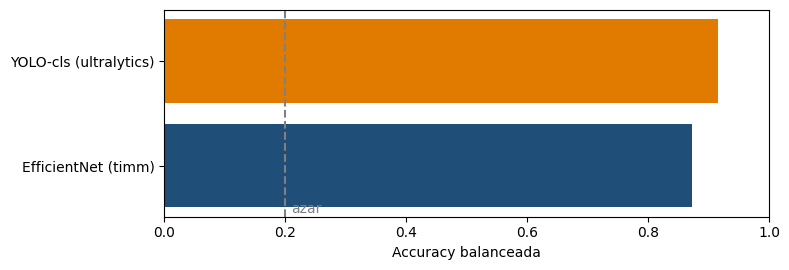

In [104]:
# Comparar el rendimiento de los modelos
plt.figure(figsize=(8,2.8))
plt.barh(list(RESULTADOS),list(RESULTADOS.values()),color=["#1f4e79","#e07b00"])
plt.axvline(0.20,ls="--",color="gray"); plt.text(0.21,-0.45,"azar",color="gray")
plt.xlim(0,1); plt.xlabel("Accuracy balanceada"); plt.tight_layout(); plt.show()

## 6. Evaluación del modelo seleccionado

Luego de comparar ambos modelos, seleccionamos YOLO por obtener una accuracy balanceada de 91,5%, superando el 87,3% alcanzado por EfficientNet. Para analizar su rendimiento con mayor detalle, utilizaremos las 620 imágenes de validación y calcularemos distintas métricas, como accuracy, precision y recall. Además, construiremos una matriz de confusión para identificar qué categorías reconoce correctamente y en cuáles presenta mayores dificultades.

In [108]:
# Importar las métricas de evaluación
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Obtener las predicciones de YOLO
reales=[c for _,c in val]
preds=[predecir_yolo(r) for r,_ in val]

# Mostrar los resultados
print("Accuracy:",round(accuracy_score(reales,preds),3))
print("Accuracy balanceada:",round(balanced_accuracy_score(reales,preds),3))
print(classification_report(reales,preds,labels=CLASES))

Accuracy: 0.91
Accuracy balanceada: 0.915
              precision    recall  f1-score   support

   Cardboard       0.93      0.88      0.91        93
       Glass       0.92      0.95      0.94        84
       Metal       0.89      0.90      0.90       158
       Paper       0.94      0.95      0.95       100
     Plastic       0.89      0.89      0.89       185

    accuracy                           0.91       620
   macro avg       0.92      0.91      0.91       620
weighted avg       0.91      0.91      0.91       620



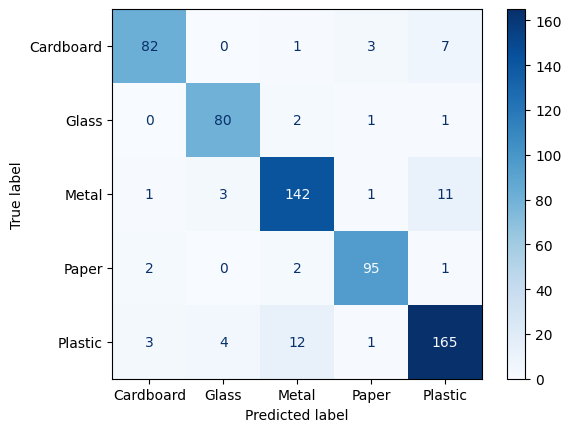

In [110]:
# Matriz de confusión
cm=confusion_matrix(reales,preds,labels=CLASES)
ConfusionMatrixDisplay(cm,display_labels=CLASES).plot(cmap="Blues")
plt.show()

Los resultados muestran que YOLO obtuvo una accuracy del 91%, clasificando correctamente 564 de las 620 imágenes de validación. Al revisar la matriz de confusión, observamos que las categorías con mejores resultados fueron vidrio y papel, ambas con un recall del 95%. Por otro lado, las principales dificultades se encuentran entre plástico y metal, ya que el modelo confundió 12 imágenes de plástico con metal y 11 de metal con plástico.

## 7. Análisis de errores

Para comprender mejor las dificultades del modelo, revisaremos algunas de las imágenes que YOLO clasificó incorrectamente. Esto nos permitirá observar qué características de los residuos podrían generar confusiones entre las distintas categorías y reconocer algunas limitaciones de nuestro modelo.

Errores: 56 de 620


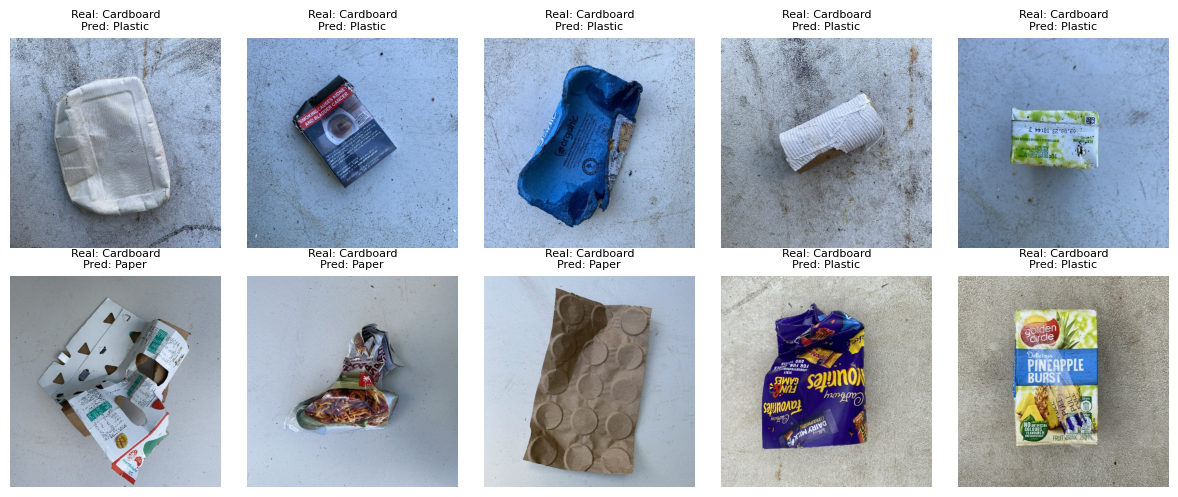

In [117]:
# Encontrar las imágenes que el modelo clasificó incorrectamente
errores=np.where(np.array(preds)!=np.array(reales))[0]
print("Errores:",len(errores),"de",len(reales))

# Mostrar los primeros 10 errores
plt.figure(figsize=(12,5))
for k,i in enumerate(errores[:10]):
    plt.subplot(2,5,k+1)
    plt.imshow(Image.open(val[i][0]).convert("RGB"))
    plt.title(f"Real: {reales[i]}\nPred: {preds[i]}",fontsize=8)
    plt.axis("off")
plt.tight_layout(); plt.show()

Al revisar las imágenes clasificadas incorrectamente, observamos que el modelo presenta dificultades para diferenciar algunos residuos de cartón y plástico. Esto podría deberse a que ciertos envases tienen recubrimientos, colores o características visuales similares a otros materiales. En total, YOLO cometió 56 errores de las 620 imágenes de validación. Esto demuestra que, aunque el modelo presenta un buen rendimiento general, todavía existen dificultades para reconocer ciertos residuos, especialmente aquellos que combinan distintos materiales o tienen apariencias similares.

## 8. Interpretación del error más costoso

Uno de los errores más relevantes que identificamos fue la confusión entre plástico y metal. Según la matriz de confusión, el modelo clasificó incorrectamente 12 imágenes de plástico como metal y 11 imágenes de metal como plástico. Este tipo de error podría generar problemas en el proceso de reciclaje, ya que separar incorrectamente estos materiales puede contaminar los residuos destinados a cada categoría y provocar un trabajo adicional para corregir su clasificación.

Metal clasificado como plástico: 11
Plástico clasificado como metal: 12


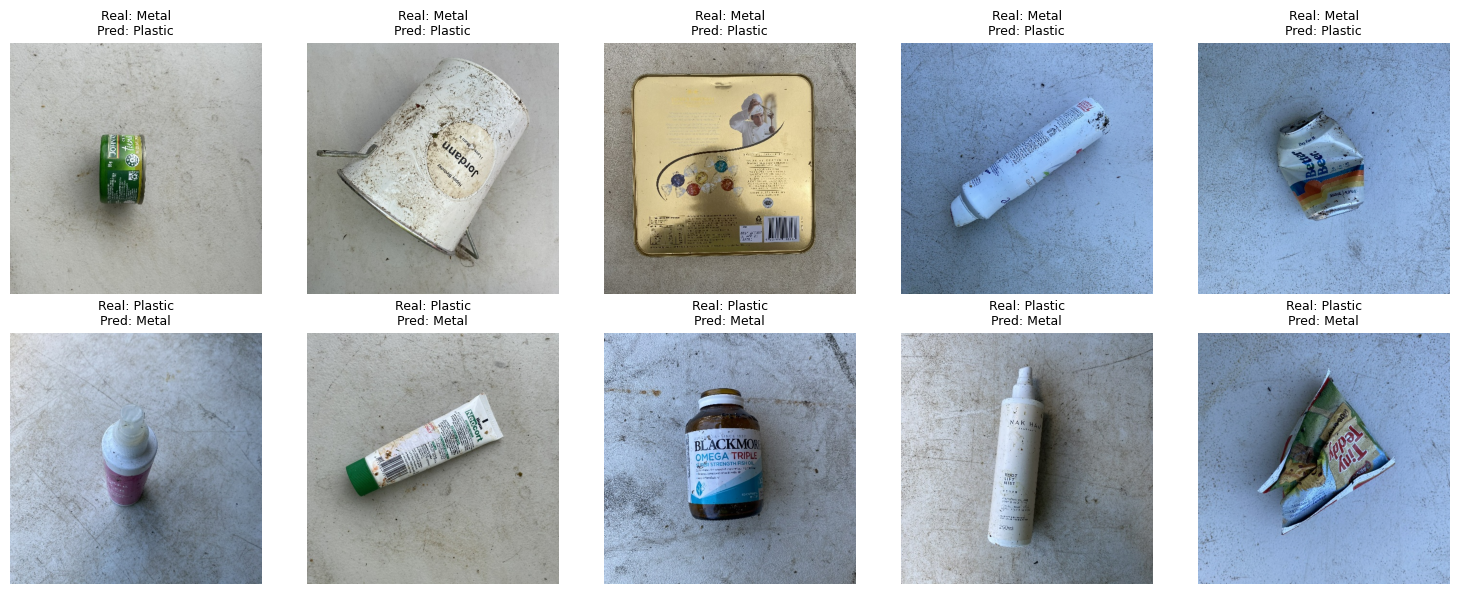

In [132]:
# Buscar errores entre Metal y Plastic
metal_a_plastic=[]
plastic_a_metal=[]

for ruta,real in val:
    pred=predecir_yolo(ruta)
    if real=="Metal" and pred=="Plastic":
        metal_a_plastic.append((ruta,real,pred))
    if real=="Plastic" and pred=="Metal":
        plastic_a_metal.append((ruta,real,pred))

# Tomar 5 ejemplos de cada tipo de error
ej_metal=random.Random(0).sample(metal_a_plastic,min(5,len(metal_a_plastic)))
ej_plastic=random.Random(1).sample(plastic_a_metal,min(5,len(plastic_a_metal)))

muestra=ej_metal+ej_plastic

print("Metal clasificado como plástico:",len(metal_a_plastic))
print("Plástico clasificado como metal:",len(plastic_a_metal))

# Mostrar 10 imágenes juntas
plt.figure(figsize=(15,6))
for k,(ruta,real,pred) in enumerate(muestra,1):
    plt.subplot(2,5,k)
    plt.imshow(Image.open(ruta).convert("RGB"))
    plt.title(f"Real: {real}\nPred: {pred}",fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

## 9. Guardado del modelo seleccionado

In [128]:
# Guardar el modelo entrenado
import shutil

os.makedirs("modelos",exist_ok=True)
shutil.copy(yolo.trainer.best,"modelos/yolo_residuos.pt")

print("Modelo guardado. Para cargarlo: YOLO('modelos/yolo_residuos.pt')")

Modelo guardado. Para cargarlo: YOLO('modelos/yolo_residuos.pt')
